In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('creditcard.csv')

print("Jumlah baris duplikat:", df.duplicated().sum())

print("5 Baris Pertama")
display(df.head())

#cek struktur data (tipe kolom, jumlah baris, dan deteksi nilai kosong/null)
print("\nInformasi Dataset")
df.info()

#cek tingkat keparahan imbalanced data di kolom target 'class'
print("\nDistribusi Kelas (0: Normal, 1: Fraud)")
print(df['Class'].value_counts())

print("\nPersentase Data")
print(df['Class'].value_counts(normalize=True) * 100)

Jumlah baris duplikat: 743
5 Baris Pertama


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0



Informasi Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210013 entries, 0 to 210012
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    210013 non-null  float64
 1   V1      210013 non-null  float64
 2   V2      210013 non-null  float64
 3   V3      210013 non-null  float64
 4   V4      210013 non-null  float64
 5   V5      210013 non-null  float64
 6   V6      210013 non-null  float64
 7   V7      210013 non-null  float64
 8   V8      210013 non-null  float64
 9   V9      210013 non-null  float64
 10  V10     210013 non-null  float64
 11  V11     210013 non-null  float64
 12  V12     210013 non-null  float64
 13  V13     210013 non-null  float64
 14  V14     210012 non-null  float64
 15  V15     210012 non-null  float64
 16  V16     210012 non-null  float64
 17  V17     210012 non-null  float64
 18  V18     210012 non-null  float64
 19  V19     210012 non-null  float64
 20  V20     210012 non-null  floa

Data Setelah Preprocessing (Standardisasi)


,scaled_amount,scaled_time,V1,V2,V3,V4,V5,V6,V7,V8,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Class
0,0.240513,-2.019477,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0.0
1,-0.351738,-2.019477,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,0.0
2,1.163737,-2.019449,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,0.0
3,0.135228,-2.019449,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0.0
4,-0.080463,-2.019422,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0.0


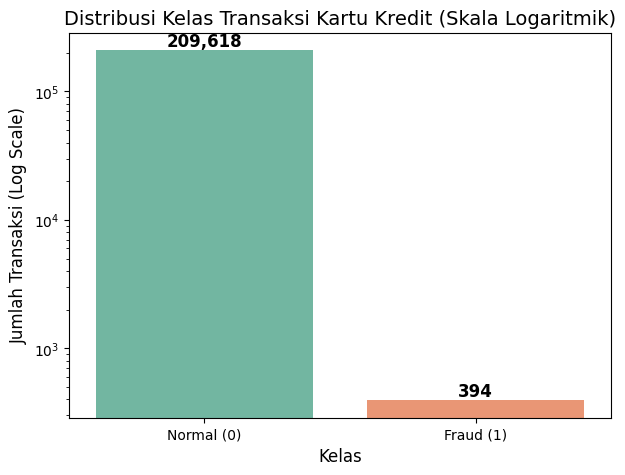

In [7]:
from sklearn.preprocessing import StandardScaler

#1. data preprocessing: standardisasi kolom time dan amount (masing-masing punya scaler sendiri)
scaler_amount = StandardScaler()
scaler_time = StandardScaler()
df['scaled_amount'] = scaler_amount.fit_transform(df[['Amount']])
df['scaled_time'] = scaler_time.fit_transform(df[['Time']])

#hapus kolom time dan amount asli, terus nempatin kolom yg distandardisasi di awal
df.drop(['Time', 'Amount'], axis=1, inplace=True)
df.insert(0, 'scaled_amount', df.pop('scaled_amount'))
df.insert(1, 'scaled_time', df.pop('scaled_time'))

print("Data Setelah Preprocessing (Standardisasi)")
display(df.head())

#2. exploratory data analysis (EDA): visualisasi imbalanced data
counts = df['Class'].value_counts().sort_index()
labels = ['Normal (0)', 'Fraud (1)']
plt.figure(figsize=(7, 5))
ax = sns.barplot(x=labels, y=counts.values, hue=labels, palette='Set2', legend=False)
#skala logaritmik agar batang fraud (492) tetap terlihat di samping normal (284.315)
ax.set_yscale('log')
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.title('Distribusi Kelas Transaksi Kartu Kredit (Skala Logaritmik)', fontsize=14)
plt.xlabel('Kelas', fontsize=12)
plt.ylabel('Jumlah Transaksi (Log Scale)', fontsize=12)
plt.show()

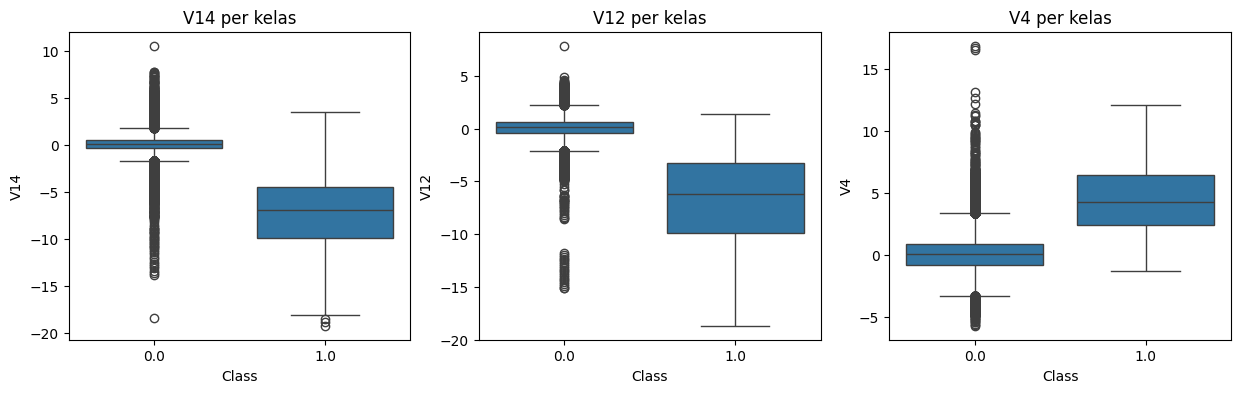

In [8]:
#EDA: bandingkan fitur penting antara transaksi normal dan fraud
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, f in zip(ax, ['V14', 'V12', 'V4']):
    sns.boxplot(x='Class', y=f, data=df, ax=a)
    a.set_title(f'{f} per kelas')
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix

#hapus baris yang ada nilai NaN/kosong
df = df.dropna()

#1. misahin fitur prediktor (X) dan target label (y)
X = df.drop('Class', axis=1)
y = df['Class']

#2. data splitting: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

#3. menghitung pembobot kelas (scale_pos_weight) utk mengatasi imbalanced data
neg_class = y_train.value_counts()[0]
pos_class = y_train.value_counts()[1]
spw = neg_class / pos_class
print(f"Nilai scale_pos_weight: {spw:.2f}")

#4. inisialisasi model XGBoost
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=spw,
    random_state=42,
    eval_metric='aucpr' #evaluasi fokus pada kurva precision-recall
)

#5. proses training
print("\nSedang melatih model XGBoost.")
xgb_model.fit(X_train, y_train)
print("Training Selesai.")

#6. prediksi dan evaluasi pada data testing
y_pred = xgb_model.predict(X_test)

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report")
print(classification_report(y_test, y_pred))

Jumlah data training: 168009
Jumlah data testing: 42003
Nilai scale_pos_weight: 532.36

Sedang melatih model XGBoost.
Training Selesai.

Confusion Matrix
[[41923     1]
 [   12    67]]

Classification Report
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     41924
         1.0       0.99      0.85      0.91        79

    accuracy                           1.00     42003
   macro avg       0.99      0.92      0.96     42003
weighted avg       1.00      1.00      1.00     42003



Visualisasi Faktor Pemicu Fraud (SHAP)


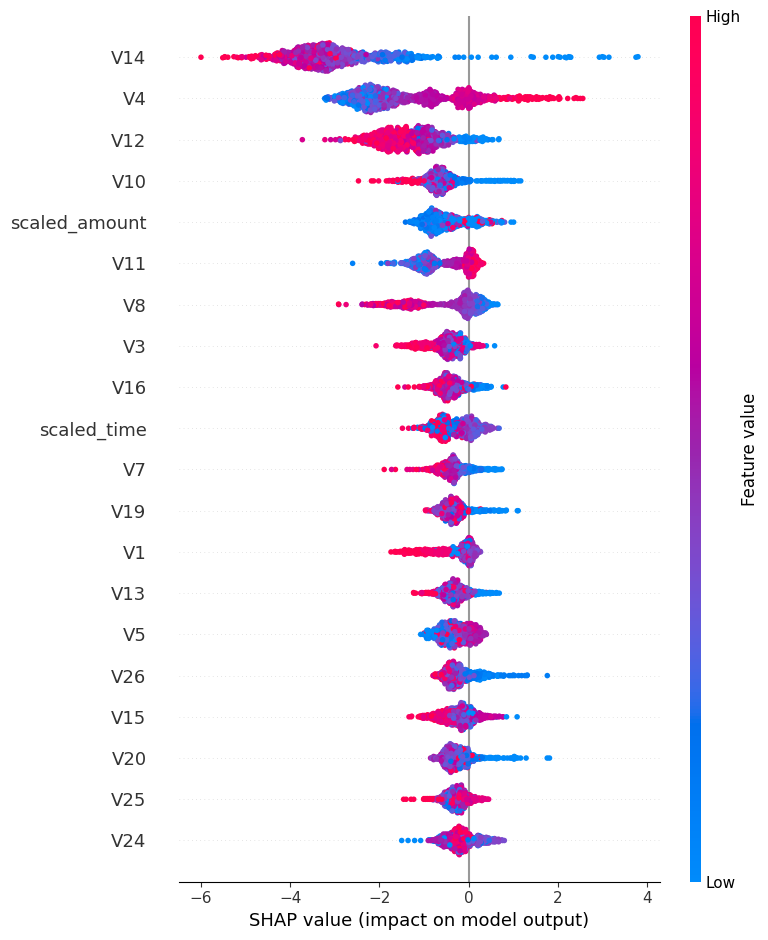

In [10]:
import shap

#1. inisialisasi SHAP TreeExplainer untuk model XGBoost
explainer = shap.TreeExplainer(xgb_model)

#2. menghitung SHAP values (karena datanya besar, ambil sampel biar ngga terlalu lama)
#ambil 1000 data acak dari X_test utk visualisasi
X_test_sample = X_test.sample(n=1000, random_state=42)
shap_values = explainer.shap_values(X_test_sample)

#3. nampilin SHAP summary plot
print("Visualisasi Faktor Pemicu Fraud (SHAP)")
shap.summary_plot(shap_values, X_test_sample)

In [11]:
import joblib

joblib.dump(xgb_model, 'xgboost_fraud_model.pkl')
xgb_model.save_model('xgboost_fraud_model.json')  #format portabel antar versi XGBoost

joblib.dump(scaler_amount, 'scaler_amount.pkl')
joblib.dump(scaler_time, 'scaler_time.pkl')

print("Model (pkl + json) dan kedua scaler berhasil disimpan.")

Model (pkl + json) dan kedua scaler berhasil disimpan.
